# Phase-3.1 — TrustFin-SLM Research Audit and Methodology Readiness

**Project:** *Trustworthy Small Language Models for Financial Tasks*  
**Input:** the completed `Phase3_TrustFin_Deliverable.zip` and, optionally, your original Phase-2.1 workspace and saved E5 adapter.  
**Output:** an independently auditable **Phase-3.1 evidence package** consumed by Phase-4.

> **Research safeguard:** Phase-3.1 audits the **existing Phase-3 validation predictions**. It never opens Phase-2.1 protected FinQA/FiQA test files, FinBen-FOMC test records, or FinTrust evaluation examples. It never silently modifies Phase-3's frozen model choice. Where original datasets, checkpoints, or official evaluation code are unavailable, the relevant gate is explicitly **PENDING**, never a fabricated PASS.

## Work packages

| Work package | Core task | Output |
|---|---|---|
| A | Structural integrity, provenance and stable record IDs | `input_inventory.csv`, `source_validation.json` |
| B | Repair invalid-program-rate bug and reproduce E1–E11 metrics | `corrected_metrics/`, `phase3_repaired_validation_metrics.csv` |
| C | Validate executable-versus-written answers; quantify opportunity | `finqa_answer_reconciliation.csv`, significance/CI |
| D | Financial operand grounding audit (optional Phase-2.1 validation data) | `operand_grounding_audit.csv`, limitation flags |
| E | Token-limit/saturation and prompt-length analysis | `truncation_audit.csv`, optional measured prompt lengths |
| F | Frozen-prompt confidence analysis and risk–coverage diagnostics | `phase4_validation_features.jsonl`, `risk_coverage.csv` |
| G | E5 model provenance + FinTrust evaluator readiness | manifests + explicit pending items |
| H | Research gates, student report and Phase-4 handoff | `phase3_1_readiness.json`, `phase4_handoff_config.json` |

**No model fine-tuning is performed in this notebook.** The optional context pilot only reruns inference on selected *validation* cases; it does not retune or overwrite E5.

## HOW TO RUN — student instructions

### Required files

- Download/copy the **original** `Phase3_TrustFin_Deliverable.zip` to the **same folder** as this notebook. You do **not** need to extract it.
- Keep Python 3.10+ and install `pandas`, `numpy`, `scipy`, `scikit-learn`, `matplotlib`, `nbformat` if necessary.
- Run **all cells in order**. Default `RUN_MODE="full"` analyzes the entire existing validation output and generally does not require CUDA, pretrained models, or network access.

### Recommended full research run

1. Run the optional installation cell only if dependencies are missing.
2. Set `PHASE3_SOURCE` in the configuration cell if the ZIP is not beside the notebook. The notebook also searches the working directory and `/mnt/data`.
3. Set `TRUSTFIN_WORKSPACE` to the directory containing `artifacts/phase2_1` and `artifacts/phase3` if available. **This enables input-grounding and local model provenance checks.**
4. Set `TRUSTFIN_E5_ADAPTER` to the actual E5 adapter folder (contains `adapter_config.json`, `.safetensors` weights). You do **not** need this for the offline metrics audit, but it is required for a reproducible Phase-4 backbone handoff.
5. Run the notebook top-to-bottom. Outputs are written to `artifacts/phase3_1/` under your chosen workspace.
6. Read `phase3_1_readiness.json`. The notebook distinguishes **offline validation PASS** from **complete Phase-4 research readiness**.
7. Resolve every `PENDING` gate. If needed, rerun Phase-3.1; it does not overwrite the original Phase-3 outputs.

### Faster smoke check

Set `RUN_MODE="smoke"` (100 FinQA + 30 FiQA rows where available). Smoke checks mechanics but **cannot freeze Phase-3.1**. Restore `RUN_MODE="full"` for the final run.

### What NOT to do

- Do not train on, tune thresholds using, or inspect gold labels from Phase-2.1 protected test sets.
- Do not replace official FinTrust scoring with a generic accuracy metric.
- Do not claim a program is grounded merely because its numeric literals occur somewhere in the full evidence.
- Do not reinterpret raw generation likelihood as calibrated probability of being correct.
- Do not revise E5/E11 model selection after observing Phase-4 test outcomes.

### Expected runtime

The **core full audit** operates on the delivered CSV/JSON files and needs only CPU. Optional verification and inference checks require your original local datasets/evaluator/adapter and potentially a CUDA GPU.

## 0. Optional dependencies (run once only when necessary)

In [1]:
INSTALL_DEPENDENCIES = False
if INSTALL_DEPENDENCIES:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m','pip','install','-U',
                           'pandas>=2.0', 'numpy>=1.24', 'scipy>=1.10',
                           'scikit-learn>=1.3', 'matplotlib>=3.7', 'nbformat>=5.0'])
    print('Restart kernel after installation, then proceed.')
else:
    print('Dependency installation skipped.')

Dependency installation skipped.


## 1. Configuration and deterministic environment

In [2]:
from __future__ import annotations
import os, json, re, io, zipfile, hashlib, inspect, math, time, sys, platform, random, importlib.util
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from scipy.stats import binomtest, spearmanr, pearsonr
from sklearn.metrics import roc_auc_score, mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

SEED = 42
RNG = np.random.default_rng(SEED)
RUN_MODE = os.environ.get('TRUSTFIN_PHASE3_1_MODE','full').strip().lower()  # 'smoke' or 'full'
assert RUN_MODE in {'smoke','full'}

# Set path to ZIP or an extracted Phase3_TrustFin_Deliverable folder, if needed.
PHASE3_SOURCE = os.environ.get('TRUSTFIN_PHASE3_SOURCE','')
WORKSPACE = Path(os.environ.get('TRUSTFIN_WORKSPACE', str(Path.cwd()))).expanduser().resolve()
OUTPUT_ROOT = Path(os.environ.get('TRUSTFIN_PHASE3_1_OUT',str(WORKSPACE/'artifacts'/'phase3_1'))).expanduser()

PHASE2_1_REGISTRY = os.environ.get('TRUSTFIN_PHASE2_1_REGISTRY','')  # Optional
PHASE2_1_VALIDATION = os.environ.get('TRUSTFIN_PHASE2_1_VALIDATION','') # Optional
E5_ADAPTER_OVERRIDE = os.environ.get('TRUSTFIN_E5_ADAPTER','')           # Optional
VERIFIED_FINTRUST_MAP = os.environ.get('TRUSTFIN_FINTRUST_EVAL_MAP','')   # Optional vetted mapping JSON

# Optional heavyweight verification/pilot switches. CPU-only default does not need these.
MEASURE_UNTRUNCATED_TOKEN_LENGTHS = True   # ENABLED: Qwen3-1.7B tokenizer verified in local HF cache (no inference; token counting only)
REEXECUTE_OFFICIAL_FINQA = True            # ENABLED: official FinQA evaluator + dev source verified locally with matching SHA-256 fingerprints
RUN_CONTEXT_PILOT = False                 # optional GPU pilot; not required for Phase-3.1 readiness (kept NOT_RUN by design)

SMOKE_FINQA = 100
SMOKE_FIQA = 30
MAX_SEQ_LENGTH_OVERRIDE = None            # Normally read Phase-3 environment manifest

for sub in ['manifests','corrected_metrics','tables','analysis','plots','phase4_interface']:
    (OUTPUT_ROOT/sub).mkdir(parents=True,exist_ok=True)

print('Mode:',RUN_MODE)
print('Workspace:',WORKSPACE)
print('Output:',OUTPUT_ROOT)
print('Python:',platform.python_version())

Mode: full
Workspace: /home/heet18/Downloads/Research Papers/notebooks
Output: /home/heet18/Downloads/Research Papers/notebooks/artifacts/phase3_1
Python: 3.12.3


## 2. Open and inventory the delivered Phase-3 ZIP/folder

In [3]:
class Phase3Bundle:
    """Read Phase-3 artifacts either from original ZIP or extracted directory.

    No protected Phase-2.1 test data is ever requested.
    """
    def __init__(self, supplied=None):
        candidates = []
        if supplied: candidates.append(Path(supplied).expanduser())
        candidates += [
            Path.cwd()/'Phase3_TrustFin_Deliverable.zip',
            Path.cwd()/'Phase3_TrustFin_Deliverable',
            Path('/mnt/data/Phase3_TrustFin_Deliverable.zip'),
            WORKSPACE/'Phase3_TrustFin_Deliverable.zip',
            WORKSPACE/'Phase3_TrustFin_Deliverable',
        ]
        found = next((x.resolve() for x in candidates if x.exists()),None)
        if found is None:
            raise FileNotFoundError('Set TRUSTFIN_PHASE3_SOURCE to the original ZIP or extracted folder.')
        self.path = found
        self.is_zip = self.path.is_file() and self.path.suffix.lower()=='.zip'
        if self.is_zip:
            self.zf=zipfile.ZipFile(self.path)
            self.names=[n for n in self.zf.namelist() if not n.endswith('/')]
        elif self.path.is_dir():
            self.zf=None
            self.names=[x.relative_to(self.path).as_posix() for x in self.path.rglob('*') if x.is_file()]
        else:
            raise ValueError('Input must be a ZIP or directory')
        self.resolved={}

    def locate(self, path):
        target=str(path).replace('\\','/').lstrip('/')
        # Narrow to the exact requested artifact; do not use fuzzy matching.
        matches=[n for n in self.names if n==target or n.endswith('/'+target)]
        if not matches:
            raise FileNotFoundError(f'Missing Phase-3 artifact: {target}')
        if len(matches)>1:
            raise RuntimeError(f'Ambiguous path for {target}: {matches}')
        return matches[0]

    def exists(self,path):
        try: self.locate(path);return True
        except FileNotFoundError: return False

    def read(self,path):
        name=self.locate(path)
        if self.is_zip:
            return self.zf.read(name)
        return (self.path/name).read_bytes()

    def json(self,path):
        return json.loads(self.read(path).decode('utf-8'))

    def csv(self,path):
        return pd.read_csv(io.BytesIO(self.read(path)), low_memory=False)

    def sha(self,path):
        return hashlib.sha256(self.read(path)).hexdigest()

    def close(self):
        if self.zf is not None: self.zf.close()
PHASE3_SOURCE = '/home/heet18/Downloads/Research Papers/deliverables/Phase3_TrustFin_Deliverable.zip'
P3='artifacts/phase3/'
BUNDLE=Phase3Bundle(PHASE3_SOURCE)
files=[x for x in BUNDLE.names]
INV=pd.DataFrame({'file':files})
INV['category']=INV['file'].str.extract(r'artifacts/phase3/([^/]+)/',expand=False).fillna('other')
INV['bytes']=INV['file'].map(lambda x: len(BUNDLE.zf.read(x)) if BUNDLE.is_zip else (BUNDLE.path/x).stat().st_size)
INV.to_csv(OUTPUT_ROOT/'tables'/'input_inventory.csv',index=False)
print('Source:',BUNDLE.path,'| ZIP:',BUNDLE.is_zip)
print('Files:',len(files));display(INV.groupby('category',dropna=False).agg(files=('file','count'),bytes=('bytes','sum')))

FREEZE=BUNDLE.json(P3+'manifests/phase3_freeze.json')
COMPLETION=BUNDLE.json(P3+'manifests/phase3_completion_report.json')
ENV=BUNDLE.json(P3+'manifests/environment.json')
assert FREEZE['winner']['experiment']=='E5', 'Expected previously frozen E5 primary backbone.'
assert FREEZE['status']=='FROZEN' and COMPLETION['phase3_complete'], 'Phase-3 not frozen/completed.'
assert FREEZE['prompt_policy']['FinQA']=='canonical'
assert FREEZE['prompt_policy']['FiQA']=='explicit_schema'
assert ENV['run_mode']=='full'
MAX_SEQ_LENGTH=int(MAX_SEQ_LENGTH_OVERRIDE or ENV['training']['max_seq_length'])
SOURCE_REPORT={'source':str(BUNDLE.path),'source_type':'zip' if BUNDLE.is_zip else 'directory',
               'zip_sha256': hashlib.sha256(BUNDLE.path.read_bytes()).hexdigest() if BUNDLE.is_zip else None,
               'phase3_freeze_sha256':BUNDLE.sha(P3+'manifests/phase3_freeze.json'),
               'phase3_environment_sha256':BUNDLE.sha(P3+'manifests/environment.json'),
               'frozen_experiment':'E5','run_mode_original':ENV['run_mode'],
               'max_seq_length':MAX_SEQ_LENGTH,'original_completion_status':COMPLETION['phase3_complete']}
(OUTPUT_ROOT/'manifests'/'source_validation.json').write_text(json.dumps(SOURCE_REPORT,indent=2),encoding='utf-8')
print('Original freeze E5 verified. Training max sequence length:',MAX_SEQ_LENGTH)

Source: /home/heet18/Downloads/Research Papers/deliverables/Phase3_TrustFin_Deliverable.zip | ZIP: True
Files: 89


,files,bytes
category,,
analysis,10,373442
manifests,5,8378
metrics,22,16395
other,35,2958178
plots,2,78012
predictions,15,6150347


Original freeze E5 verified. Training max sequence length: 1024


## 3. Load E1–E11 predictions with stable *validation* sample identities

In [4]:
CORE_IDS=['E1','E2','E3','E4','E5','E6','E7','E8','E11']
PROMPT_IDS=['E9_canonical','E9_no_task_token','E9_explicit_schema',
            'E10_canonical','E10_no_task_token','E10_explicit_schema']

def prediction_file(e):return P3+f'predictions/{e}.csv'

def read_predictions(e):
    df=BUNDLE.csv(prediction_file(e))
    required={'dataset','record_id','prompt_tokens','confidence','parse_success'}
    missing=required-set(df.columns)
    assert not missing,f'{e} missing columns: {missing}'
    assert df['record_id'].notna().all(),f'{e}: missing record IDs'
    assert not df['record_id'].duplicated().any(),f'{e}: duplicate record IDs'
    assert set(df['dataset'].unique()) <= {'FinQA','FiQA'}
    if RUN_MODE=='smoke':
        parts=[]
        for ds,cap in [('FinQA',SMOKE_FINQA),('FiQA',SMOKE_FIQA)]:
            p=df[df['dataset']==ds].sort_values('record_id')
            parts.append(p.head(cap))
        return pd.concat(parts,ignore_index=True)
    return df

PRED={e:read_predictions(e) for e in CORE_IDS+PROMPT_IDS}
REF_IDS=set(PRED['E5']['record_id'])
for e in CORE_IDS:
    assert set(PRED[e]['record_id'])==REF_IDS,f'{e}: validation identity mismatch vs E5'
if RUN_MODE=='full':
    assert len(PRED['E5'])==1000
    assert dict(PRED['E5']['dataset'].value_counts())=={'FinQA':883,'FiQA':117}
for e in PROMPT_IDS:
    ds='FinQA' if e.startswith('E9') else 'FiQA'
    expected=set(PRED['E5'].query('dataset == @ds')['record_id'])
    assert set(PRED[e]['record_id'])==expected,(e,'prompt ablation record IDs differ')

pd.DataFrame([{'experiment':e,'n':len(d),'datasets':str(dict(d['dataset'].value_counts())),
               'input_sha256':BUNDLE.sha(prediction_file(e))}
              for e,d in PRED.items()]).to_csv(OUTPUT_ROOT/'tables'/'prediction_inventory.csv',index=False)
print('Loaded records with exact alignment:',len(REF_IDS))

Loaded records with exact alignment: 1000


## 4. Repair the negative invalid-program-rate bug

The original Phase-3 evaluation applied a bitwise inversion to object-typed Booleans in some cases. That produced impossible negative rates such as `−1.9966`. Here we explicitly parse Boolean columns before computing:

\[ invalid\_program\_rate = 1 - \mathrm{mean}(program\_executable). \]

**Original metrics are preserved.** All corrected metrics are stored in a new Phase-3.1 directory. Report both differences and exact sample counts.

In [5]:
TRUE_VALUES={True,1,'1','true','t','yes'}
FALSE_VALUES={False,0,'0','false','f','no'}
def bool_series(s):
    def convert(v):
        if pd.isna(v):return False
        if isinstance(v,str):return v.strip().lower() in {'1','true','t','yes'}
        return bool(v)
    return s.map(convert).astype(bool)

def numerical(s):
    return pd.to_numeric(s,errors='coerce')

def strict_metrics(df):
    ans={};f=df[df.dataset=='FinQA'];q=df[df.dataset=='FiQA']
    if len(f):
        fields={key:bool_series(f[key]) for key in ['parse_success','program_correct','answer_correct',
                                                   'program_executable','execution_correct']}
        ans['FinQA']={'n':len(f),'parse_success':float(fields['parse_success'].mean()),
                      'answer_accuracy':float(fields['answer_correct'].mean()),
                      'program_accuracy':float(fields['program_correct'].mean()),
                      'execution_accuracy':float(fields['execution_correct'].mean()),
                      'invalid_program_rate':float(1.0-fields['program_executable'].mean()),
                      'invalid_program_count':int((~fields['program_executable']).sum())}
    if len(q):
        gold=numerical(q['gold_score']);pred=numerical(q['pred_score'])
        legal=gold.notna() & pred.notna(); y=gold[legal].to_numpy(float);x=pred[legal].to_numpy(float)
        clipped=np.clip(x,-1,1)
        met={'n':len(q),'parse_success':float(bool_series(q['parse_success']).mean()),
             'out_of_range_prediction_count':int(((x<-1)|(x>1)).sum()),
             'scored_examples':int(len(x))}
        if len(x):
            mse=float(mean_squared_error(y,clipped));
            met.update({'mae':float(mean_absolute_error(y,clipped)),'mse':mse,'rmse':float(np.sqrt(mse)),
                        'r2':float(r2_score(y,clipped)) if len(y)>1 else None,
                        'pearson_r':float(pearsonr(y,clipped).statistic) if len(y)>2 and np.std(y)>0 and np.std(clipped)>0 else None,
                        'mae_without_clipping':float(mean_absolute_error(y,x))})
        ans['FiQA']=met
    latency=numerical(df['latency_seconds']); tokens=numerical(df['generated_tokens'])
    ans['Efficiency']={'n':len(df),'mean_latency_seconds':float(latency.mean()),
                       'median_latency_seconds':float(latency.median()),
                       'tokens_per_second':float(tokens.sum()/latency.sum()) if latency.sum()>0 else None,
                       'mean_prompt_tokens':float(numerical(df['prompt_tokens']).mean()),
                       'mean_generated_tokens':float(tokens.mean())}
    return ans

def save_json(obj,path):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(obj,indent=2,ensure_ascii=False,default=str),encoding='utf-8')

REPAIRED={};changes=[];flat=[]
for e,d in PRED.items():
    out=strict_metrics(d); REPAIRED[e]=out
    save_json(out,OUTPUT_ROOT/'corrected_metrics'/f'{e}.json')
    if BUNDLE.exists(P3+f'metrics/{e}.json'):
        orig=BUNDLE.json(P3+f'metrics/{e}.json')
        for ds in ['FinQA','FiQA']:
            for key,value in out.get(ds,{}).items():
                if key in orig.get(ds,{}) and isinstance(value,(int,float)) and value is not None:
                    old=orig[ds][key]
                    if old is not None and np.isfinite(value) and abs(float(old)-float(value))>1e-8:
                        changes.append({'experiment':e,'task':ds,'metric':key,'original':old,
                                        'corrected':value,'difference':float(value-float(old))})
    fr={'experiment':e}
    for ds in ['FinQA','FiQA','Efficiency']:
        fr.update({ds+'.'+k:v for k,v in out.get(ds,{}).items()})
    flat.append(fr)
CHANGES=pd.DataFrame(changes)
CHANGES.to_csv(OUTPUT_ROOT/'tables'/'metric_corrections.csv',index=False)
CORRECTED=pd.DataFrame(flat).sort_values('experiment')
CORRECTED.to_csv(OUTPUT_ROOT/'tables'/'phase3_repaired_validation_metrics.csv',index=False)
assert all(0<=x['FinQA']['invalid_program_rate']<=1 for x in REPAIRED.values() if 'FinQA' in x)
print('Corrections:',len(CHANGES));display(CHANGES.head(25));display(CORRECTED.head(12))

Corrections: 9


,experiment,task,metric,original,corrected,difference
0,E1,FinQA,invalid_program_rate,-1.000000,1.000000,2.0
1,E2,FinQA,invalid_program_rate,-1.000000,1.000000,2.0
2,E3,FinQA,invalid_program_rate,-1.988675,0.011325,2.0
3,E4,FinQA,invalid_program_rate,-1.000000,1.000000,2.0
4,E5,FinQA,invalid_program_rate,-1.996602,0.003398,2.0
5,E6,FinQA,invalid_program_rate,-1.000000,1.000000,2.0
6,E7,FinQA,invalid_program_rate,-1.109853,0.890147,2.0
7,E8,FinQA,invalid_program_rate,-1.996602,0.003398,2.0
8,E11,FinQA,invalid_program_rate,-1.994337,0.005663,2.0


,experiment,FinQA.n,FinQA.parse_success,FinQA.answer_accuracy,FinQA.program_accuracy,FinQA.execution_accuracy,FinQA.invalid_program_rate,FinQA.invalid_program_count,FiQA.n,FiQA.parse_success,...,FiQA.rmse,FiQA.r2,FiQA.pearson_r,FiQA.mae_without_clipping,Efficiency.n,Efficiency.mean_latency_seconds,Efficiency.median_latency_seconds,Efficiency.tokens_per_second,Efficiency.mean_prompt_tokens,Efficiency.mean_generated_tokens
0,E1,883.0,0.013590,0.004530,0.000000,0.000000,1.000000,883.0,117.0,1.000000,...,0.622116,-1.786614,0.684000,0.500521,1000,3.398192,4.185188,44.070198,821.593000,149.759000
12,E10_canonical,NaN,NaN,NaN,NaN,NaN,NaN,NaN,117.0,1.000000,...,0.193624,0.730069,0.873217,0.130103,117,0.463234,0.465182,23.303292,121.128205,10.794872
14,E10_explicit_schema,NaN,NaN,NaN,NaN,NaN,NaN,NaN,117.0,1.000000,...,0.190849,0.737751,0.874246,0.127291,117,0.468747,0.478133,23.029229,137.128205,10.794872
13,E10_no_task_token,NaN,NaN,NaN,NaN,NaN,NaN,NaN,117.0,1.000000,...,0.194337,0.728079,0.872625,0.130359,117,0.461460,0.465340,23.318798,117.128205,10.760684
8,E11,883.0,1.000000,0.344281,0.554926,0.614949,0.005663,5.0,117.0,1.000000,...,0.191651,0.735542,0.873656,0.127581,1000,1.199309,1.180162,25.347928,821.593000,30.400000
1,E2,883.0,0.000000,0.000000,0.000000,0.000000,1.000000,883.0,117.0,1.000000,...,0.270797,0.472014,0.805849,0.185068,1000,3.083744,3.682240,48.537105,950.305000,149.676000
2,E3,883.0,1.000000,0.389581,0.624009,0.680634,0.011325,10.0,117.0,0.606838,...,0.597177,-1.839797,0.469402,0.504724,1000,1.187762,1.163553,24.697705,821.593000,29.335000
3,E4,883.0,0.000000,0.000000,0.000000,0.000000,1.000000,883.0,117.0,1.000000,...,0.195447,0.724963,0.863956,0.129453,1000,2.345942,1.536160,22.550430,821.593000,52.902000
4,E5,883.0,1.000000,0.375991,0.611552,0.674972,0.003398,3.0,117.0,1.000000,...,0.193624,0.730069,0.873217,0.130103,1000,1.179324,1.161947,24.500481,821.593000,28.894000
5,E6,883.0,0.028313,0.000000,0.000000,0.000000,1.000000,883.0,117.0,1.000000,...,0.447855,-0.444136,0.814589,0.381479,1000,3.336588,3.811465,43.955080,772.516000,146.660000


## 5. Paired baseline comparisons and 95% bootstrap uncertainty

In [6]:
def mcnemar_exact(d1,d2,field='execution_correct'):
    a=d1[['record_id',field]].merge(d2[['record_id',field]],on='record_id',suffixes=('_a','_b'),validate='one_to_one')
    av=bool_series(a[field+'_a']);bv=bool_series(a[field+'_b'])
    b=int((av & ~bv).sum()); c=int((~av & bv).sum())
    return {'n':len(a),'a_only_correct':b,'b_only_correct':c,
            'delta_pp':float((av.mean()-bv.mean())*100),
            'exact_mcnemar_p':float(binomtest(min(b,c),b+c,p=.5,alternative='two-sided').pvalue) if b+c else 1.0}

paired=[]
for alt in ['E3','E8','E11']:
    a=PRED['E5'].query('dataset=="FinQA"');b=PRED[alt].query('dataset=="FinQA"')
    r=mcnemar_exact(a,b);r.update({'model_a':'E5','model_b':alt})
    paired.append(r)
PAIRED=pd.DataFrame(paired)
PAIRED.to_csv(OUTPUT_ROOT/'tables'/'paired_model_comparisons.csv',index=False)
display(PAIRED)

,n,a_only_correct,b_only_correct,delta_pp,exact_mcnemar_p,model_a,model_b
0,883,37,42,-0.566251,0.652964,E5,E3
1,883,58,81,-2.604757,0.061649,E5,E8
2,883,95,42,6.002265,0.000007,E5,E11


## 6. FinQA written-answer vs program-execution reconciliation

This audits **already saved validation predictions**, including exact disagreement counts. It does not regenerate outputs or treat an executable yet incorrect program as trustworthy.

A deterministic replacement of the written `ANSWER` with the result of an executable program can improve **answer reporting**, but does **not** repair reasoning errors in the program itself.

FinQA written vs executed


,0
n,883
written_correct,332
written_accuracy,0.375991
executed_correct,596
executed_accuracy,0.674972
absolute_gain_pp,29.898075
bootstrap_95pct_gain_pp,"[26.953567383918458, 32.955832389580976]"
outcome_counts,"{'both_correct': 331, 'execution_only_correct'..."
text_and_execution_agree,498
text_and_execution_disagree,385


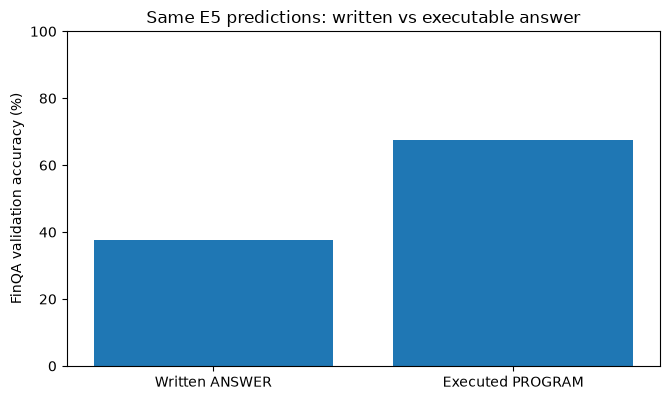

In [7]:
f=PRED['E5'].query('dataset=="FinQA"').copy()
f['text_correct']=bool_series(f['answer_correct']); f['exec_correct']=bool_series(f['execution_correct'])
f['executable']=bool_series(f['program_executable'])
conditions=[f.text_correct & f.exec_correct, ~f.text_correct & f.exec_correct,
            f.text_correct & ~f.exec_correct,~f.text_correct & ~f.exec_correct]
labels=['both_correct','execution_only_correct','text_only_correct','both_wrong']
f['answer_execution_outcome']=np.select(conditions,labels,default='unclassified')

def parse_num(value):
    if value is None or (isinstance(value,float) and not np.isfinite(value)):return None
    s=str(value).strip().replace(',','').replace('$','')
    pct=s.endswith('%');s=s[:-1].strip() if pct else s
    try:
        v=float(s)
        return v/100 if pct else v
    except Exception:return None

def answer_agreement(a,b):
    if pd.isna(a) or pd.isna(b):return False
    x,y=parse_num(a),parse_num(b)
    if x is not None and y is not None:
        return bool(np.isclose(x,y,rtol=1e-3,atol=1e-4))
    return str(a).strip().lower()==str(b).strip().lower()

f['text_agrees_executed']= [answer_agreement(a,b) for a,b in zip(f.pred_answer,f.executed_answer)]
f['post_execution_correct']=f['exec_correct']
f['answer_changed_if_executed']=f['executable'] & (~f['text_agrees_executed'])
f.to_csv(OUTPUT_ROOT/'analysis'/'finqa_answer_reconciliation.csv',index=False)
counts=f['answer_execution_outcome'].value_counts().reindex(labels,fill_value=0)
n=len(f);text_acc=f.text_correct.mean();exec_acc=f.exec_correct.mean()
bootstrap=np.random.default_rng(SEED)
a=(f.exec_correct.astype(int)-f.text_correct.astype(int)).to_numpy()
samples=bootstrap.integers(0,len(a),size=(2500,len(a)))
lo,hi=np.percentile(a[samples].mean(axis=1)*100,[2.5,97.5]);
SUMMARY={'n':n,'written_correct':int(f.text_correct.sum()),'written_accuracy':float(text_acc),
         'executed_correct':int(f.exec_correct.sum()),'executed_accuracy':float(exec_acc),
         'absolute_gain_pp':float((exec_acc-text_acc)*100),
         'bootstrap_95pct_gain_pp':[float(lo),float(hi)],
         'outcome_counts':counts.to_dict(),
         'text_and_execution_agree':int(f.text_agrees_executed.sum()),
         'text_and_execution_disagree':int((~f.text_agrees_executed).sum()),
         'changed_by_execution':int(f.answer_changed_if_executed.sum()),
         'warning':'Correct execution of a predicted program does not establish that the chosen program is correct.'}
save_json(SUMMARY,OUTPUT_ROOT/'analysis'/'finqa_reconciliation_summary.json')
print('FinQA written vs executed');display(pd.DataFrame([SUMMARY]).T)
fig,ax=plt.subplots(figsize=(6.8,4.1))
ax.bar(['Written ANSWER','Executed PROGRAM'],[100*text_acc,100*exec_acc])
ax.set_ylabel('FinQA validation accuracy (%)');ax.set_ylim(0,100)
ax.set_title('Same E5 predictions: written vs executable answer')
fig.tight_layout();fig.savefig(OUTPUT_ROOT/'plots'/'answer_execution_gap.png',dpi=170);plt.show()

## 7. Optional Phase-2.1 **validation-only** data contract and hash checks

In [8]:
def first_existing(seq):
    return next((Path(x).expanduser().resolve() for x in seq if x and Path(x).expanduser().exists()),None)

REG_PATH=first_existing([
    PHASE2_1_REGISTRY,
    WORKSPACE/'artifacts/phase2_1/manifests/dataset_registry.json',
    Path(FREEZE['data']['phase2_1_registry']),
])
VAL_PATH=first_existing([
    PHASE2_1_VALIDATION,
    WORKSPACE/'artifacts/phase2_1/datasets/validation.jsonl',
    Path(FREEZE['data']['validation_path']),
])

def file_sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as inp:
        for part in iter(lambda:inp.read(4*1024*1024),b''):
            h.update(part)
    return h.hexdigest()

REGISTRY=None;VALIDATION=None;VALIDATION_BY_ID={};data_gates={}
if REG_PATH:
    digest=file_sha(REG_PATH)
    assert digest==FREEZE['data']['registry_sha256'], 'PHASE2.1 REGISTRY HASH MISMATCH. Stop.'
    REGISTRY=json.loads(REG_PATH.read_text(encoding='utf-8'))
    data_gates['registry_hash']='PASS'
else:
    data_gates['registry_hash']='PENDING: supply Phase-2.1 registry'

if VAL_PATH:
    digest=file_sha(VAL_PATH)
    assert digest==FREEZE['data']['validation_sha256'], 'PHASE2.1 VALIDATION HASH MISMATCH. Stop.'
    with VAL_PATH.open('r',encoding='utf-8') as inp:
        VALIDATION=[json.loads(x) for x in inp if x.strip()]
    VALIDATION_BY_ID={r['record_id']:r for r in VALIDATION}
    assert len(VALIDATION_BY_ID)==len(VALIDATION)==1000
    assert set(PRED['E5'].record_id).issubset(VALIDATION_BY_ID)
    assert set(r['dataset'] for r in VALIDATION)=={'FinQA','FiQA'}
    assert all(not r.get('metadata',{}).get('evaluation_only',False) for r in VALIDATION)
    data_gates['validation_hash']='PASS'
else:
    data_gates['validation_hash']='PENDING: supply Phase-2.1 validation.jsonl'

save_json(data_gates,OUTPUT_ROOT/'manifests'/'phase2_1_connection.json')
print('Optional Phase-2.1 connection:',data_gates)

Optional Phase-2.1 connection: {'registry_hash': 'PASS', 'validation_hash': 'PASS'}


## 8. Heuristic financial-number grounding audit

If the original Phase-2.1 *validation* records are present, this cell checks whether a **numeric literal used in a generated FinQA program** has a matching numeric occurrence somewhere in the original evidence. Constants (`const_100`, etc.) and prior-step references (`#0`) are handled separately.

**Interpretation limitation:** Numeric occurrence is **not sufficient to prove correct evidence use**, and a missing literal may still be derived or represented differently. This audit is a triage signal only. Further, the original `input` may be longer than the context actually visible to a length-capped model. Both limitations are retained in the result fields.

In [9]:
OP_NUM=re.compile(r'(?<![\w#])[-+]?(?:\d[\d,]*(?:\.\d+)?|\.\d+)(?![\w])')
EXCLUDE_CONST=re.compile(r'const_[-+]?\d+(?:\.\d+)?',re.I)
EXCLUDE_REF=re.compile(r'#\d+')

def digits(text):
    text=EXCLUDE_CONST.sub(' ',str(text or ''))
    text=EXCLUDE_REF.sub(' ',text)
    return [float(z.replace(',','')) for z in OP_NUM.findall(text)]

def literal_matches(target,available):
    return any(np.isclose(target,q,rtol=1e-5,atol=1e-6) for q in available)

if VALIDATION is not None:
    ground=[]
    for _,r in f.iterrows():
        rec=VALIDATION_BY_ID.get(r.record_id,{})
        pred_nums=digits(r.pred_program)
        inp_nums=digits(rec.get('input',''))
        unmatched=[z for z in pred_nums if not literal_matches(z,inp_nums)]
        ground.append({'record_id':r.record_id,'source_id':r.source_id,
                       'literal_count':len(pred_nums),'unmatched_literal_count':len(unmatched),
                       'unmatched_literals':json.dumps(unmatched),
                       'all_literals_in_full_input':len(unmatched)==0,
                       'execution_correct':bool(r.exec_correct),
                       'prompt_at_length_cap':int(r.prompt_tokens)>=MAX_SEQ_LENGTH,
                       'limitation':'Presence in original full input; not proof of semantic support or model-visible context.'})
    GROUND=pd.DataFrame(ground)
    GROUND.to_csv(OUTPUT_ROOT/'analysis'/'operand_grounding_audit.csv',index=False)
    GROUND_SUM={'status':'HEURISTIC_AUDIT_COMPLETED','n':len(GROUND),
                'any_unmatched_count':int((GROUND.unmatched_literal_count>0).sum()),
                'unmatched_literal_total':int(GROUND.unmatched_literal_count.sum()),
                'method':'literal number appears anywhere in original Phase-2.1 validation evidence',
                'caution':'Neither numerically present nor missing literals prove semantic correctness.'}
else:
    GROUND=None
    GROUND_SUM={'status':'PENDING_VALIDATION_INPUT','message':'Provide validated Phase-2.1 validation.jsonl to enable numeric-literal grounding audit.'}
save_json(GROUND_SUM,OUTPUT_ROOT/'analysis'/'operand_grounding_summary.json')
print(GROUND_SUM)

{'status': 'HEURISTIC_AUDIT_COMPLETED', 'n': 883, 'any_unmatched_count': 19, 'unmatched_literal_total': 28, 'method': 'literal number appears anywhere in original Phase-2.1 validation evidence', 'caution': 'Neither numerically present nor missing literals prove semantic correctness.'}


## 9. Saturated model-input analysis and optional exact tokenizer-length check

In [10]:
cap=int(MAX_SEQ_LENGTH)
trunc_rows=[]
for exp in ['E3','E5','E8','E11']:
    x=PRED[exp].query('dataset=="FinQA"').copy()
    x['at_or_above_limit']=numerical(x.prompt_tokens)>=cap
    x['execution_correct_bool']=bool_series(x.execution_correct)
    trunc_rows.append({'experiment':exp,'n':len(x),'cap':cap,'at_cap_n':int(x.at_or_above_limit.sum()),
                       'at_cap_fraction':float(x.at_or_above_limit.mean()),
                       'execution_accuracy_at_cap':float(x.loc[x.at_or_above_limit,'execution_correct_bool'].mean()) if x.at_or_above_limit.any() else None,
                       'execution_accuracy_below_cap':float(x.loc[~x.at_or_above_limit,'execution_correct_bool'].mean()) if (~x.at_or_above_limit).any() else None})
E8_TRAIN_META=BUNDLE.json(P3+'metrics/E8_training.json')
TRUNC_SUM=pd.DataFrame(trunc_rows)
TRUNC_SUM['train_max_seq_length']=TRUNC_SUM['experiment'].map(lambda exp: E8_TRAIN_META.get('train_max_seq_length',MAX_SEQ_LENGTH) if exp=='E8' else MAX_SEQ_LENGTH)
TRUNC_SUM['note']='All listed evaluation predictions used the 1024-token cap; E8 training used a shorter cap.'
TRUNC_SUM.to_csv(OUTPUT_ROOT/'tables'/'truncation_summary.csv',index=False)
trunc=f[['record_id','source_id','prompt_tokens','execution_correct','answer_correct','confidence']].copy()
trunc['reached_token_cap']=numerical(trunc.prompt_tokens)>=cap
trunc['length_cap']=cap
trunc.to_csv(OUTPUT_ROOT/'analysis'/'truncation_audit.csv',index=False)
display(TRUNC_SUM)
print('NOTE: reaching the cap is an upper-bound proxy; actual truncation requires raw tokenizer-length measurement.')

,experiment,n,cap,at_cap_n,at_cap_fraction,execution_accuracy_at_cap,execution_accuracy_below_cap,train_max_seq_length,note
0,E3,883,1024,460,0.520951,0.663043,0.699764,1024,All listed evaluation predictions used the 102...
1,E5,883,1024,460,0.520951,0.636957,0.716312,1024,All listed evaluation predictions used the 102...
2,E8,883,1024,325,0.368063,0.701538,0.700717,768,All listed evaluation predictions used the 102...
3,E11,883,1024,460,0.520951,0.508696,0.730496,1024,All listed evaluation predictions used the 102...


NOTE: reaching the cap is an upper-bound proxy; actual truncation requires raw tokenizer-length measurement.


### 9A. Optional exact prompt-length measurement

This **does not run inference**. If the Phase-2.1 validation records and a locally cached tokenizer are available, enable `MEASURE_UNTRUNCATED_TOKEN_LENGTHS=True` and rerun this cell. It reconstructs the canonical Phase-3 prompts, counts tokens **before truncation**, and compares them with the saved token limits. The tokenizer must match the model revision used in Phase-3.

In [11]:
TOK_AUDIT={'status':'NOT_RUN','reason':'Enable MEASURE_UNTRUNCATED_TOKEN_LENGTHS and provide local validated Phase-2.1 validation data.'}
if MEASURE_UNTRUNCATED_TOKEN_LENGTHS:
    if VALIDATION is None: raise RuntimeError('Phase-2.1 validation.jsonl required.')
    from transformers import AutoTokenizer
    tok=AutoTokenizer.from_pretrained(FREEZE['winner']['model_id'],local_files_only=True,trust_remote_code=True)
    if tok.pad_token_id is None: tok.pad_token=tok.eos_token
    def phase3_messages(r):
        return [{'role':'system','content':r['system']},
                {'role':'user','content':f"<FINQA>\n{r['instruction'].strip()}\n\n{r['input'].strip()}"}]
    def render_messages(msg):
        try:return tok.apply_chat_template(msg,tokenize=False,add_generation_prompt=True,enable_thinking=False)
        except TypeError:return tok.apply_chat_template(msg,tokenize=False,add_generation_prompt=True)
    actual=[]
    for rid in f.record_id:
        r=VALIDATION_BY_ID[rid]
        raw_prompt=render_messages(phase3_messages(r))
        original_len=len(tok(raw_prompt,add_special_tokens=False,truncation=False)['input_ids'])
        actual.append({'record_id':rid,'untruncated_prompt_tokens':original_len,
                       'truly_truncated':original_len>cap,'cap':cap})
    TRUE_TOK=pd.DataFrame(actual)
    TRUE_TOK.to_csv(OUTPUT_ROOT/'analysis'/'exact_prompt_lengths.csv',index=False)
    TOK_AUDIT={'status':'MEASURED','examples':len(TRUE_TOK),'true_truncation_n':int(TRUE_TOK.truly_truncated.sum()),
               'true_truncation_rate':float(TRUE_TOK.truly_truncated.mean()),
               'tokenizer':FREEZE['winner']['model_id']}
save_json(TOK_AUDIT,OUTPUT_ROOT/'analysis'/'exact_prompt_length_status.json')
print(TOK_AUDIT)

/home/heet18/retail-shelf-intelligence/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'status': 'MEASURED', 'examples': 883, 'true_truncation_n': 459, 'true_truncation_rate': 0.5198187995469988, 'tokenizer': 'Qwen/Qwen3-1.7B'}


## 10. Recalculate confidence on the **frozen task-specific prompts**

Phase-3 froze `FinQA = canonical` and `FiQA = explicit_schema`; the Phase-3 E5 confidence report used the canonical variant for both. This cell **joins E9-canonical and E10-explicit-schema** to construct a faithful Phase-4 calibration development set. It does not select or freeze an abstention threshold.

Outputs distinguish **FinQA correctness discrimination** from **FiQA continuous-regression error**. Sequence likelihood is an uncalibrated score, not a trustworthy posterior probability.

In [12]:
finconf=PRED['E9_canonical'].copy()
fiqaconf=PRED['E10_explicit_schema'].copy()
assert set(finconf.record_id)==set(f.record_id)
CONFSET=pd.concat([finconf,fiqaconf],ignore_index=True)
assert len(CONFSET)==len(PRED['E5'])

conf_audits=[];risk_rows=[]
for ds in ['FinQA','FiQA']:
    d=CONFSET[CONFSET.dataset==ds].copy()
    d['confidence']=numerical(d['confidence'])
    valid=np.isfinite(d['confidence'])
    d=d[valid].copy()
    if ds=='FinQA':
        y=bool_series(d['execution_correct']).astype(int).to_numpy()
        score=d['confidence'].to_numpy(float)
        auc=float(roc_auc_score(y,score)) if len(np.unique(y))==2 else None
        sp=float(spearmanr(score,y).statistic) if len(np.unique(score))>1 else None
        conf_audits.append({'dataset':ds,'n':len(d),'confidence_auc_on_execution_correct':auc,
                            'spearman_confidence_correctness':sp,
                            'warning':'ROC-AUC is discrimination, not calibrated probability.'})
        d=d.sort_values(['confidence','record_id'],ascending=[False,True])
        for cov in [1.,.9,.8,.7,.5]:
            k=max(1,int(np.ceil(cov*len(d))));sub=d.head(k)
            risk_rows.append({'dataset':ds,'target_coverage':cov,'actual_coverage':len(sub)/len(d),
                              'accepted_n':len(sub),'risk':float(1-bool_series(sub.execution_correct).mean()),
                              'metric':'incorrect_execution_rate','selection':'sort_by_unscaled_sequence_likelihood'})
    else:
        score=d.confidence.to_numpy(float)
        err=np.abs(numerical(d.pred_score).to_numpy(float)-numerical(d.gold_score).to_numpy(float))
        mask=np.isfinite(err)
        corr=float(spearmanr(score[mask],-err[mask]).statistic) if mask.sum()>2 and np.std(score[mask])>0 and np.std(err[mask])>0 else None
        conf_audits.append({'dataset':ds,'n':int(mask.sum()),'spearman_confidence_negative_abs_error':corr,
                            'warning':'Use selective MAE, not classification-style ECE on a regression target.'})
        d=d.assign(abs_error=err).sort_values(['confidence','record_id'],ascending=[False,True])
        for cov in [1.,.9,.8,.7,.5]:
            k=max(1,int(np.ceil(cov*len(d))));sub=d.head(k)
            risk_rows.append({'dataset':ds,'target_coverage':cov,'actual_coverage':len(sub)/len(d),
                              'accepted_n':len(sub),'risk':float(sub.abs_error.mean()),
                              'metric':'selective_MAE','selection':'sort_by_unscaled_sequence_likelihood'})

CONF_AUDIT=pd.DataFrame(conf_audits)
RISK=pd.DataFrame(risk_rows)
CONF_AUDIT.to_csv(OUTPUT_ROOT/'tables'/'confidence_audit.csv',index=False)
RISK.to_csv(OUTPUT_ROOT/'tables'/'risk_coverage.csv',index=False)
display(CONF_AUDIT);display(RISK)

,dataset,n,confidence_auc_on_execution_correct,spearman_confidence_correctness,warning,spearman_confidence_negative_abs_error
0,FinQA,883,0.576901,0.124774,"ROC-AUC is discrimination, not calibrated prob...",NaN
1,FiQA,117,NaN,NaN,"Use selective MAE, not classification-style EC...",0.098063


,dataset,target_coverage,actual_coverage,accepted_n,risk,metric,selection
0,FinQA,1.0,1.000000,883,0.325028,incorrect_execution_rate,sort_by_unscaled_sequence_likelihood
1,FinQA,0.9,0.900340,795,0.309434,incorrect_execution_rate,sort_by_unscaled_sequence_likelihood
2,FinQA,0.8,0.800680,707,0.302687,incorrect_execution_rate,sort_by_unscaled_sequence_likelihood
3,FinQA,0.7,0.701019,619,0.308562,incorrect_execution_rate,sort_by_unscaled_sequence_likelihood
4,FinQA,0.5,0.500566,442,0.328054,incorrect_execution_rate,sort_by_unscaled_sequence_likelihood
5,FiQA,1.0,1.000000,117,0.127291,selective_MAE,sort_by_unscaled_sequence_likelihood
6,FiQA,0.9,0.905983,106,0.118774,selective_MAE,sort_by_unscaled_sequence_likelihood
7,FiQA,0.8,0.803419,94,0.113149,selective_MAE,sort_by_unscaled_sequence_likelihood
8,FiQA,0.7,0.700855,82,0.104085,selective_MAE,sort_by_unscaled_sequence_likelihood
9,FiQA,0.5,0.504274,59,0.097898,selective_MAE,sort_by_unscaled_sequence_likelihood


## 11. Export clean **Phase-4 validation features**, with deterministic calibration subfolds

In [13]:
# Stable splitting of the Phase-2.1 *validation* identities only: no protected data loaded.
# This diagnostic split is NOT an independent final test set.
def fold_from_id(s):
    v=int(hashlib.sha256(str(s).encode('utf-8')).hexdigest()[:8],16)
    return 'calibration_holdout' if v%5==0 else 'calibration_fit'

features=[]
GROUND_LOOKUP=GROUND.set_index('record_id') if GROUND is not None else None
for _,r in CONFSET.iterrows():
    ds=r.dataset
    row={'record_id':r.record_id,'source_id':r.source_id,'dataset':ds,
         'phase2_split':'validation','calibration_fold':fold_from_id(r.record_id),
         'model_experiment':'E5','frozen_prompt_variant':str(r.prompt_variant),
         'mean_logprob':None if pd.isna(r.mean_logprob) else float(r.mean_logprob),
         'sequence_likelihood_score':None if pd.isna(r.confidence) else float(r.confidence),
         'generated_tokens':int(r.generated_tokens),'prompt_tokens':int(r.prompt_tokens),
         'prompt_reaches_cap':bool(int(r.prompt_tokens)>=MAX_SEQ_LENGTH),
         'parse_success':bool(r.parse_success)}
    if ds=='FinQA':
        row.update({'program_executable':bool(r.program_executable),
                    'generated_answer_agrees_with_execution':answer_agreement(r.pred_answer,r.executed_answer),
                    'execution_correct_validation_label':bool(r.execution_correct),
                    'answer_correct_validation_label':bool(r.answer_correct),
                    'program_exact_match_validation_label':bool(r.program_correct)})
        if GROUND_LOOKUP is not None:
            gr=GROUND_LOOKUP.loc[r.record_id]
            row['unmatched_literal_count_in_full_input']=int(gr.unmatched_literal_count)
        else:row['unmatched_literal_count_in_full_input']=None
    else:
        row.update({'predicted_sentiment':None if pd.isna(r.pred_score) else float(r.pred_score),
                    'gold_sentiment_validation_label':float(r.gold_score),
                    'absolute_error_validation_label':abs(float(r.pred_score)-float(r.gold_score)) if not pd.isna(r.pred_score) else None})
    features.append(row)
feat_path=OUTPUT_ROOT/'phase4_interface'/'phase4_validation_features.jsonl'
with feat_path.open('w',encoding='utf-8') as out:
    for r in features: out.write(json.dumps(r,ensure_ascii=False)+'\n')

FOLD_COUNTS=pd.DataFrame(features).groupby(['dataset','calibration_fold']).size().reset_index(name='n')
FOLD_COUNTS.to_csv(OUTPUT_ROOT/'tables'/'calibration_subfold_counts.csv',index=False)
print('Phase-4 validation feature records:',len(features));display(FOLD_COUNTS)

Phase-4 validation feature records: 1000


,dataset,calibration_fold,n
0,FiQA,calibration_fit,92
1,FiQA,calibration_holdout,25
2,FinQA,calibration_fit,698
3,FinQA,calibration_holdout,185


## 12. Optional independent execution with the **official FinQA evaluator**

The saved Phase-3 prediction files include executed results, but without the original table and official evaluator we cannot independently re-execute those programs. Enable `REEXECUTE_OFFICIAL_FINQA=True` only if the Phase-2.1 workspace contains those files. If unavailable, this remains PENDING and Phase-3.1 must not claim independent reproduction.

In [14]:
OFFICIAL_STATUS={'status':'NOT_RUN','reason':'Set REEXECUTE_OFFICIAL_FINQA=True with Phase-2.1 registry/config and source files available.'}
OFFICIAL_MODULE=None;RAW_DEV_TABLES={}
if REEXECUTE_OFFICIAL_FINQA:
    assert REGISTRY is not None, 'Provide Phase-2.1 dataset_registry.json.'
    p4=first_existing([WORKSPACE/'artifacts/phase2_1/manifests/phase4_eval_config.json',
                       REG_PATH.parent/'phase4_eval_config.json'])
    assert p4, 'Cannot find Phase-2.1 phase4_eval_config.json.'
    p4cfg=json.loads(p4.read_text(encoding='utf-8'))
    evaluator=first_existing([os.environ.get('TRUSTFIN_FINQA_EVALUATOR',''),
                              p4cfg['official_evaluators'].get('FinQA_local','')])
    assert evaluator and file_sha(evaluator)==p4cfg['official_evaluators']['FinQA_sha256'], 'Official FinQA evaluator missing/hash mismatch.'
    fingerprints_path=first_existing([REGISTRY.get('source_fingerprints',''), REG_PATH.parent/'source_fingerprints.json'])
    assert fingerprints_path, 'Source fingerprints not available.'
    fp=json.loads(fingerprints_path.read_text(encoding='utf-8'))
    dev=first_existing([os.environ.get('TRUSTFIN_FINQA_DEV_JSON',''),fp['FinQA']['dev']['path']])
    assert dev and file_sha(dev)==fp['FinQA']['dev']['sha256'], 'FinQA raw dev source missing/hash mismatch.'
    raw=json.loads(dev.read_text(encoding='utf-8'))
    RAW_DEV_TABLES={str(r['id']):r['table'] for r in raw}
    spec=importlib.util.spec_from_file_location('official_finqa_phase3_1',str(evaluator))
    OFFICIAL_MODULE=importlib.util.module_from_spec(spec);spec.loader.exec_module(OFFICIAL_MODULE)
    official_rows=[]
    for _,r in f.iterrows():
        ok=False;result=None    
        try:
            tokens=OFFICIAL_MODULE.program_tokenization(r.pred_program)
            invalid,result=OFFICIAL_MODULE.eval_program(tokens,RAW_DEV_TABLES[str(r.source_id)])
            ok=int(invalid)==0
        except Exception:pass
        saved_ok=bool(r.executable)
        saved_result=r.executed_answer
        agree=ok==saved_ok and ((not ok) or answer_agreement(result,saved_result))
        official_rows.append({'record_id':r.record_id,'official_executable':ok,'official_result':result,
                              'saved_executable':saved_ok,'saved_result':saved_result,'match_saved':agree})
    EXEC_AUDIT=pd.DataFrame(official_rows)
    EXEC_AUDIT.to_csv(OUTPUT_ROOT/'analysis'/'official_execution_reaudit.csv',index=False)
    OFFICIAL_STATUS={'status':'PASS' if EXEC_AUDIT.match_saved.all() else 'FAIL',
                     'n':len(EXEC_AUDIT),'mismatch_count':int((~EXEC_AUDIT.match_saved).sum()),
                     'evaluator_sha256':file_sha(evaluator),'raw_dev_sha256':file_sha(dev)}
save_json(OFFICIAL_STATUS,OUTPUT_ROOT/'manifests'/'official_executor_status.json')
print(OFFICIAL_STATUS)

{'status': 'PASS', 'n': 883, 'mismatch_count': 0, 'evaluator_sha256': '845cd131cab843eceff256cf6d392978cc470a7da4a80107beb56027fdca5c13', 'raw_dev_sha256': 'a847fb7e0d61a3125a1e2909852df6b89f1ee64d2c5ff1bf689e332214deee51'}


## 13. Checkpoint hashing and environment reconciliation

In [15]:
ADAPTER=first_existing([
    E5_ADAPTER_OVERRIDE,
    WORKSPACE/'artifacts/phase3/checkpoints/E5',
    FREEZE['winner']['adapter_path'],
])
CHECKPOINT_STATUS={'status':'PENDING_CHECKPOINT','expected_base_model':FREEZE['winner']['model_id']}
if ADAPTER and ADAPTER.is_dir() and (ADAPTER/'adapter_config.json').exists():
    adapter_conf=json.loads((ADAPTER/'adapter_config.json').read_text(encoding='utf-8'))
    adapter_base=adapter_conf.get('base_model_name_or_path')
    files_to_hash=sorted([x for x in ADAPTER.rglob('*') if x.is_file() and 'trainer_tmp' not in x.parts])
    hashes=[{'relative_path':x.relative_to(ADAPTER).as_posix(), 'size_bytes':x.stat().st_size,
             'sha256':file_sha(x)} for x in files_to_hash]
    has_weights=any(x.name.endswith('.safetensors') or x.name.endswith('.bin') for x in files_to_hash)
    base_ok=adapter_base in [FREEZE['winner']['model_id'],None]
    CHECKPOINT_STATUS={'status':'PASS' if has_weights and base_ok else 'FAIL',
                       'path':str(ADAPTER),'adapter_base_model':adapter_base,
                       'expected_base_model':FREEZE['winner']['model_id'],
                       'weight_files_present':has_weights,'base_model_matches':base_ok,
                       'files':hashes,
                       'model_revision_note':'Pin underlying HF commit revision before final reproducibility release.'}
else:
    CHECKPOINT_STATUS['message']='Original ZIP does not include adapter weights. Set TRUSTFIN_E5_ADAPTER to the original local E5 checkpoint.'
save_json(CHECKPOINT_STATUS,OUTPUT_ROOT/'manifests'/'e5_checkpoint_manifest.json')
ENV_REVIEW={'manifest_python':ENV.get('python'),'manifest_torch':ENV.get('torch'),
            'manifest_transformers':ENV.get('packages',{}).get('transformers'),
            'manifest_cuda':ENV.get('cuda_runtime'),
            'original_experiment_E5':BUNDLE.json(P3+'metrics/E5_training.json'),
            'E8_training_max_seq_length':BUNDLE.json(P3+'metrics/E8_training.json').get('train_max_seq_length'),
            'E8_evaluation_max_seq_length':MAX_SEQ_LENGTH,
            'current_python':platform.python_version(),
            'note':'The current audit environment need not match training; cite the Phase-3 exported environment as authoritative unless original logs prove otherwise.'}
save_json(ENV_REVIEW,OUTPUT_ROOT/'manifests'/'environment_reconciliation.json')
print('Checkpoint status:',CHECKPOINT_STATUS['status'])

Checkpoint status: PASS


## 14. FinTrust evaluator readiness: explicitly verify **all seven dimensions**

This stage reads only the Phase-2.1 **registry metadata** and optional expert-approved evaluator mapping, never FinTrust evaluation examples. Script-discovery candidates are **not equivalent to validated official metrics**. If `TRUSTFIN_FINTRUST_EVAL_MAP` is not supplied, the seven entries remain PENDING even when a candidate script is present.

Expected optional JSON mapping (all seven dimension keys, each with `reviewed: true`, `evaluator_path`, `official_metric`, `protocol_reference`, `fixture_test_passed: true`, and `fixture_report_path`):

```json
{
  "trustfulness": {"reviewed": true, "evaluator_path": "/path/script.py", "official_metric": "...", "protocol_reference": "...", "fixture_test_passed": true, "fixture_report_path": "/path/fixture_audit.json"}
}
```

Never fill these fields speculatively. Students must document verified official evaluation procedures.

In [16]:
DIMENSIONS=['trustfulness','robustness','safety','fairness','privacy','transparency','knowledge_discovery']
ft_mapping={}
if VERIFIED_FINTRUST_MAP and Path(VERIFIED_FINTRUST_MAP).exists():
    ft_mapping=json.loads(Path(VERIFIED_FINTRUST_MAP).read_text(encoding='utf-8'))

fintrust_registry_info={}
if REGISTRY is not None:
    ft_meta=REGISTRY.get('artifacts',{}).get('fintrust_registry',{})
    ft_path=first_existing([ft_meta.get('path',''),REG_PATH.parent/'fintrust_registry.json'])
    if ft_path and ft_meta.get('sha256') and file_sha(ft_path)==ft_meta['sha256']:
        # This is *metadata only*. We do not read protected evaluation examples.
        try:
            meta=json.loads(ft_path.read_text(encoding='utf-8'))
            fintrust_registry_info={'registry_path':str(ft_path),'registry_sha256':file_sha(ft_path),
                                    'type':type(meta).__name__}
        except Exception as e:
            fintrust_registry_info={'error':str(e)}

rows=[]
for dim in DIMENSIONS:
    info=ft_mapping.get(dim,{})
    script=Path(str(info.get('evaluator_path',''))).expanduser()
    fixture_path=Path(str(info.get('fixture_report_path',''))).expanduser()
    accepted=(info.get('reviewed') is True and script.is_file() and
              info.get('fixture_test_passed') is True and fixture_path.is_file() and
              bool(str(info.get('official_metric','')).strip()) and
              bool(str(info.get('protocol_reference','')).strip()))
    rows.append({'dimension':dim,'status':'FIXTURE_VERIFIED' if accepted else 'PENDING_REVIEW',
                 'official_metric':info.get('official_metric',''),
                 'evaluator_path':str(script) if info.get('evaluator_path') else '',
                 'protocol_reference':info.get('protocol_reference',''),
                 'evaluator_sha256':file_sha(script) if accepted else '',
                 'fixture_report_sha256':file_sha(fixture_path) if accepted else '',
                 'note':'Evaluator path, official metric and nonprotected fixture test verified.' if accepted else 'Map official evaluator and demonstrate a PASS on nonprotected fixture data.'})
FT_READY=pd.DataFrame(rows)
FT_READY.to_csv(OUTPUT_ROOT/'tables'/'fintrust_evaluator_readiness.csv',index=False)
save_json(fintrust_registry_info,OUTPUT_ROOT/'manifests'/'fintrust_registry_metadata.json')
print('Verified metadata:',int((FT_READY.status=='FIXTURE_VERIFIED').sum()),'of 7')
display(FT_READY)

Verified metadata: 0 of 7


,dimension,status,official_metric,evaluator_path,protocol_reference,evaluator_sha256,fixture_report_sha256,note
0,trustfulness,PENDING_REVIEW,,,,,,Map official evaluator and demonstrate a PASS ...
1,robustness,PENDING_REVIEW,,,,,,Map official evaluator and demonstrate a PASS ...
2,safety,PENDING_REVIEW,,,,,,Map official evaluator and demonstrate a PASS ...
3,fairness,PENDING_REVIEW,,,,,,Map official evaluator and demonstrate a PASS ...
4,privacy,PENDING_REVIEW,,,,,,Map official evaluator and demonstrate a PASS ...
5,transparency,PENDING_REVIEW,,,,,,Map official evaluator and demonstrate a PASS ...
6,knowledge_discovery,PENDING_REVIEW,,,,,,Map official evaluator and demonstrate a PASS ...


## 15. Optional evidence-preserving **validation prompt pilot**

Enable `RUN_CONTEXT_PILOT=True` only after the full offline audit, original E5 weights, Phase-2.1 validation data, and the official FinQA executor are locally available. This short pilot compares **frozen canonical E5** with a question-/table-preserving compressed prompt for selected long validation inputs. It does **not** use gold answers or gold programs while constructing the compressed prompt.

It is an *exploratory diagnostic*, not a new final prompt policy. If it looks promising, pre-register a larger Phase-4 validation comparison before testing.

In [17]:
PILOT_STATUS={'status':'NOT_RUN','reason':'Optional GPU validation pilot; set RUN_CONTEXT_PILOT=True with local model/evaluator.'}
if RUN_CONTEXT_PILOT:
    if VALIDATION is None or CHECKPOINT_STATUS['status']!='PASS':
        raise RuntimeError('Context pilot requires Phase-2.1 validation and verified E5 checkpoint.')
    if OFFICIAL_MODULE is None:
        raise RuntimeError('First set REEXECUTE_OFFICIAL_FINQA=True so the official executor is available.')
    import torch
    from transformers import AutoTokenizer,AutoModelForCausalLM,BitsAndBytesConfig
    from peft import PeftModel
    assert torch.cuda.is_available(),'GPU required for the optional inference pilot.'
    tokenizer=AutoTokenizer.from_pretrained(FREEZE['winner']['model_id'],trust_remote_code=True)
    if tokenizer.pad_token_id is None:tokenizer.pad_token=tokenizer.eos_token
    tokenizer.truncation_side='left'
    quant=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
                            bnb_4bit_use_double_quant=True,
                            bnb_4bit_compute_dtype=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16)
    model=AutoModelForCausalLM.from_pretrained(FREEZE['winner']['model_id'],device_map='auto',quantization_config=quant,trust_remote_code=True)
    model=PeftModel.from_pretrained(model,str(ADAPTER));model.eval()

    def compress_evidence(rec):
        text=rec['input'];question=text.split('Question:')[-1].strip()
        before=text.split('Question:')[0]
        parts=before.split('Financial table:')
        passages=parts[0].replace('Financial text:','').splitlines()
        table_lines=parts[1].splitlines() if len(parts)>1 else []
        qterms=set(re.findall(r'[a-z]{3,}',question.lower()))
        def score(line):
            toks=set(re.findall(r'[a-z]{3,}',line.lower()))
            return len(qterms.intersection(toks))
        # Question is kept verbatim. Table header is kept if present.
        chosen_table=table_lines[:1]+sorted(table_lines[1:],key=score,reverse=True)[:14]
        chosen_text=sorted(passages,key=score,reverse=True)[:8]
        return ('Financial text:\n'+'\n'.join(chosen_text)+'\n\nFinancial table:\n'+
                '\n'.join(chosen_table)+'\n\nQuestion:\n'+question)

    long_f=f[numerical(f.prompt_tokens)>=MAX_SEQ_LENGTH].sort_values('record_id').head(24)
    outputs=[]
    for _,r in long_f.iterrows():
        rec=VALIDATION_BY_ID[r.record_id]
        user=f"<FINQA>\n{rec['instruction'].strip()}\n\n{compress_evidence(rec)}"
        messages=[{'role':'system','content':rec['system']},{'role':'user','content':user}]
        try: prompt=tokenizer.apply_chat_template(messages,tokenize=False,add_generation_prompt=True,enable_thinking=False)
        except TypeError: prompt=tokenizer.apply_chat_template(messages,tokenize=False,add_generation_prompt=True)
        ids=tokenizer(prompt,return_tensors='pt',truncation=True,max_length=MAX_SEQ_LENGTH).to(next(model.parameters()).device)
        with torch.no_grad(): generated=model.generate(**ids,max_new_tokens=192,do_sample=False,pad_token_id=tokenizer.pad_token_id)
        text=tokenizer.decode(generated[0][ids['input_ids'].shape[-1]:],skip_special_tokens=True)
        match=re.search(r'PROGRAM\s*:\s*(.+?)(?=\n\s*ANSWER\s*:|$)',text,flags=re.I|re.S)
        program=match.group(1).strip() if match else None
        exe_ok=False;exe_result=None
        try:
            inv,exe_result=OFFICIAL_MODULE.eval_program(OFFICIAL_MODULE.program_tokenization(program),RAW_DEV_TABLES[str(r.source_id)])
            exe_ok=int(inv)==0
        except Exception:pass
        success=exe_ok and answer_agreement(exe_result,r.gold_answer)
        outputs.append({'record_id':r.record_id,'baseline_exec_correct':bool(r.exec_correct),
                        'pilot_exec_correct':bool(success),'pilot_executable':bool(exe_ok),
                        'pilot_prompt_tokens':int(ids['input_ids'].shape[-1]),
                        'raw_generated':text})
    pilot=pd.DataFrame(outputs);pilot.to_csv(OUTPUT_ROOT/'analysis'/'context_pilot_predictions.csv',index=False)
    PILOT_STATUS={'status':'RUN','n':len(pilot),
                  'baseline_execution_accuracy':float(pilot.baseline_exec_correct.mean()),
                  'pilot_execution_accuracy':float(pilot.pilot_exec_correct.mean()),
                  'warning':'Exploratory validation-only prompt comparison. Do not switch frozen prompt automatically.'}
    del model,tokenizer
save_json(PILOT_STATUS,OUTPUT_ROOT/'analysis'/'context_pilot_status.json')
print(PILOT_STATUS)

{'status': 'NOT_RUN', 'reason': 'Optional GPU validation pilot; set RUN_CONTEXT_PILOT=True with local model/evaluator.'}


## 16. Phase-4 methodology handoff and research-readiness gates

Phase-3.1 must distinguish:

- **Offline analytical PASS:** E1–E16 source integrity, corrected metrics, prediction alignment, answer reconciliation and frozen-prompt diagnostics reproduced from the delivered ZIP.
- **Full Phase-4 research readiness:** all locally reproducible frozen checkpoints, independent official execution checks and verified FinTrust metric mappings resolved. Optional future context pilot may remain separate if its outcome is not claimed.

The handoff **cannot unfreeze E5** and must not include protected-test labels.

In [18]:
required_full=('full'==RUN_MODE)
validation_ok=len(PRED['E5'])==1000 if required_full else False
metric_ok=all(0<=r['FinQA']['invalid_program_rate']<=1 for r in REPAIRED.values() if 'FinQA' in r)
source_ok=FREEZE['status']=='FROZEN' and FREEZE['winner']['experiment']=='E5'
base_gates=[
 {'gate':'original E5 freeze preserved','status':'PASS' if source_ok else 'FAIL'},
 {'gate':'all E1–E11 + prompt ablation prediction IDs align','status':'PASS'},
 {'gate':'all invalid-program rates repaired and bounded','status':'PASS' if metric_ok else 'FAIL'},
 {'gate':'FinQA answer/program reconciliation exported','status':'PASS' if len(f)>0 else 'FAIL'},
 {'gate':'frozen task-specific confidence analyzed','status':'PASS' if len(CONFSET)>0 else 'FAIL'},
 {'gate':'full 1,000-example validation used','status':'PASS' if validation_ok else ('SMOKE_ONLY' if RUN_MODE=='smoke' else 'FAIL')},
 {'gate':'Phase-2.1 validation data fingerprint verified','status':data_gates['validation_hash'].split(':')[0]},
 {'gate':'original official FinQA re-execution','status':OFFICIAL_STATUS['status']},
 {'gate':'E5 checkpoint fingerprinted','status':CHECKPOINT_STATUS['status']},
 {'gate':'7 FinTrust evaluator protocols mapped','status':'PASS' if (FT_READY.status=='FIXTURE_VERIFIED').all() else 'PENDING'},
]
GATES=pd.DataFrame(base_gates)
GATES.to_csv(OUTPUT_ROOT/'tables'/'research_gates.csv',index=False)
core_done=all(x['status']=='PASS' for x in base_gates[:5]) and validation_ok
full_ready=core_done and data_gates['validation_hash']=='PASS' and OFFICIAL_STATUS['status']=='PASS' and CHECKPOINT_STATUS['status']=='PASS' and (FT_READY.status=='FIXTURE_VERIFIED').all()
READINESS={'phase':'Phase-3.1','mode':RUN_MODE,'core_offline_audit':'PASS' if core_done else 'INCOMPLETE',
           'phase4_research_readiness':'PASS' if full_ready else 'CONDITIONAL_HOLD',
           'frozen_model':'E5','frozen_model_name':FREEZE['winner']['model_id'],
           'frozen_prompts':{'FinQA':'canonical','FiQA':'explicit_schema'},
           'original_phase3_freeze_sha256':SOURCE_REPORT['phase3_freeze_sha256'],
           'source':'validation-only Phase-3 predictions',
           'no_protected_test_access':True,
           'gates':base_gates,
           'actions_if_conditional_hold':[
              'Supply frozen original Phase-2.1 validation/registry and verify recorded hashes.',
              'Re-execute the saved E5 programs using the official FinQA evaluator and dev source.',
              'Verify the exact E5 adapter files and base-model revision.',
              'Verify official FinTrust task-specific metric/evaluator implementations before Phase-4 protected evaluations.',
           ],
           'next_phase':'Phase-4A verifier then Phase-4B calibrated selective prediction, validation-only before protected test.'}
save_json(READINESS,OUTPUT_ROOT/'manifests'/'phase3_1_readiness.json')

HANDOFF={'schema_version':'trustfin.phase3_1.v1',
         'frozen_experiment':'E5','base_model':FREEZE['winner']['model_id'],
         'adapter_path':str(ADAPTER) if ADAPTER else None,
         'adapter_sha256_files':CHECKPOINT_STATUS.get('files',[]),
         'model_frozen_before_test':True,
         'prompts':{'FinQA':'canonical','FiQA':'explicit_schema'},
         'calibration_source':'Phase-2.1 validation only',
         'risk_features':str((OUTPUT_ROOT/'phase4_interface'/'phase4_validation_features.jsonl').resolve()),
         'calibration_subfold_rule':'sha256(record_id) first 8 hex chars modulo 5; 0 is holdout, others fit',
         'phase4_baselines':['E5 written output','E5 executed output','E5 likelihood-only selective prediction',
                             'E5 verifier-aware calibrated risk','E8 cross-family comparison'],
         'recommended_validation_metrics':{'FinQA':['execution accuracy','corrected answer accuracy','risk vs coverage','AURC'],
                                           'FiQA':['MAE','MSE','R2','selective MAE'],
                                           'FinTrust':['official seven-dimension, task-specific metrics only']},
         'protected_test_policy':'No protected test used in Phase-3.1. Freeze all verifier/threshold settings before Phase-4 test.',
         'source_provenance':str((OUTPUT_ROOT/'manifests'/'source_validation.json').resolve()),
         'phase4_research_readiness':READINESS['phase4_research_readiness']}
save_json(HANDOFF,OUTPUT_ROOT/'phase4_interface'/'phase4_handoff_config.json')
print('PHASE-3.1 OFFLINE AUDIT:',READINESS['core_offline_audit'])
print('PHASE-4 RESEARCH READINESS:',READINESS['phase4_research_readiness'])
display(GATES)

PHASE-3.1 OFFLINE AUDIT: PASS
PHASE-4 RESEARCH READINESS: CONDITIONAL_HOLD


,gate,status
0,original E5 freeze preserved,PASS
1,all E1–E11 + prompt ablation prediction IDs align,PASS
2,all invalid-program rates repaired and bounded,PASS
3,FinQA answer/program reconciliation exported,PASS
4,frozen task-specific confidence analyzed,PASS
5,"full 1,000-example validation used",PASS
6,Phase-2.1 validation data fingerprint verified,PASS
7,original official FinQA re-execution,PASS
8,E5 checkpoint fingerprinted,PASS
9,7 FinTrust evaluator protocols mapped,PENDING


## 17. Generate a concise student report and shareable review ZIP

In [19]:
report=[
'# TrustFin-SLM: Phase-3.1 Student Audit',
'',f"- Mode: **{RUN_MODE}**",
f"- Core offline audit: **{READINESS['core_offline_audit']}**",
f"- Full Phase-4 research readiness: **{READINESS['phase4_research_readiness']}**",
'- Primary frozen SLM: **E5 Qwen3-1.7B, balanced FinQA+FiQA QLoRA**.',
'- Frozen prompts: FinQA canonical; FiQA explicit-schema.',
'', '## Key FinQA validation observations',
f"- Written answers correct: **{SUMMARY['written_correct']}/{SUMMARY['n']}** ({100*SUMMARY['written_accuracy']:.2f}%).",
f"- Executed programs correct: **{SUMMARY['executed_correct']}/{SUMMARY['n']}** ({100*SUMMARY['executed_accuracy']:.2f}%).",
f"- Potential reporting correction: **+{SUMMARY['absolute_gain_pp']:.2f} percentage points** (paired bootstrap 95% CI {SUMMARY['bootstrap_95pct_gain_pp'][0]:.2f}–{SUMMARY['bootstrap_95pct_gain_pp'][1]:.2f}).",
f"- Execution correct but written answer wrong: **{SUMMARY['outcome_counts']['execution_only_correct']}**.",
'- CAUTION: program execution cannot detect a valid but semantically incorrect operation.',
'', '## FinQA invalid-program bug',
'- Original negative invalid-program rates are impossible; repaired files are in corrected_metrics/.',
'- No Phase-3 source prediction file is overwritten.',
'', '## Context, grounding, confidence',
f"- Original Phase-3 maximum sequence length: {MAX_SEQ_LENGTH} tokens.",
'- Reaching the token cap is not itself proof of actual truncation.',
f"- Numeric-literal grounding status: {GROUND_SUM['status']}.",
'- Confidence measured with frozen task-specific prompts; no abstention threshold selected.',
'', '## Research gates',
]
report.extend([f"- **{r['status']}** — {r['gate']}" for r in base_gates])
repro_line=('Local Phase-2.1 validation/registry fingerprints verified and the E5 adapter weights fingerprinted (see manifests/); no protected test data was accessed.'
            if (data_gates.get('validation_hash')=='PASS' and CHECKPOINT_STATUS.get('status')=='PASS') else
            'The delivered ZIP lacks model weights and Phase-2.1 validation data. Those checks remain PENDING unless linked locally.')
report.extend(['','## Recommended next steps',
'1. Keep E5 frozen; use program execution to correct written numerical output.',
'2. Develop explicit operation/numeric-source/type verification on FinQA validation.',
'3. Fit verifier-aware selective-risk scores on validation calibration-fit and assess on calibration-holdout.',
'4. Apply official task-specific FinTrust evaluators only after verified mapping.',
'5. Lock Phase-4 methodology *before* opening protected test sets.',
'', '## Important reproducibility constraint',
repro_line])
(OUTPUT_ROOT/'phase3_1_student_summary.md').write_text('\n'.join(report),encoding='utf-8')

# A concise package (excluding raw Phase-3 deliverable and sensitive model weights).
review=OUTPUT_ROOT/'Phase3_1_Review_Package.zip'
with zipfile.ZipFile(review,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for x in OUTPUT_ROOT.rglob('*'):
        if x.is_file() and x!=review:
            z.write(x,arcname=x.relative_to(OUTPUT_ROOT).as_posix())
print('Saved:',review)
print('Share executed notebook + review package with the supervisor.')

Saved: /home/heet18/Downloads/Research Papers/notebooks/artifacts/phase3_1/Phase3_1_Review_Package.zip
Share executed notebook + review package with the supervisor.


# Final checklist: files to share for the Phase-4 go/no-go decision

Run the notebook in **full** mode and share:

1. **Executed `Phase3_1_TrustFin_Research_Audit_and_Methodology_Readiness.ipynb`**.
2. The automatically generated **`Phase3_1_Review_Package.zip`** from `artifacts/phase3_1/`.
3. Most important individual artifacts (all also inside the ZIP):
   - `manifests/phase3_1_readiness.json`
   - `tables/phase3_repaired_validation_metrics.csv`
   - `tables/metric_corrections.csv`
   - `analysis/finqa_reconciliation_summary.json`
   - `tables/paired_model_comparisons.csv`
   - `analysis/operand_grounding_summary.json`
   - `tables/truncation_summary.csv`
   - `tables/confidence_audit.csv` and `tables/risk_coverage.csv`
   - `manifests/e5_checkpoint_manifest.json`
   - `manifests/official_executor_status.json`
   - `tables/fintrust_evaluator_readiness.csv`
   - `phase4_interface/phase4_validation_features.jsonl`
   - `phase4_interface/phase4_handoff_config.json`

**PASS criterion:** `core_offline_audit=PASS` confirms the supplied Phase-3 validation evidence was checked. `phase4_research_readiness=PASS` requires the local dataset/evaluator/checkpoint/FinTrust validations as well. A conditional hold is a useful finding, not a failed notebook execution.